# Social and Environmental Impact of Air Quality by AGEB — Monterrey Metropolitan Area

| Medida | Pregunta | Gráfica |
|---|---|---|
| 1. Exposición ponderada por población (PWE), global y por grupo sensible | ¿Cuánto PM2.5 respira en promedio una persona, y respiran más los niños, los adultos mayores y las personas con discapacidad? | Barras con IC 95 % y razón vs población total |
| 2a. Población por encima de la norma | ¿Cuántas personas viven, día a día, en AGEBs que rebasan el límite de 24 h de la NOM-025-SSA1-2021 y la guía de la OMS? | Serie diaria y barras por grado de marginación |
| 2b. Curva e índice de concentración | ¿La exposición se concentra en los AGEBs más marginados? | Curva de concentración |
| 3. LISA bivariado | ¿Dónde coinciden espacialmente la marginación y la contaminación alta (hotspots)? | Mapa de clústeres y diagrama de Moran |

**Fuentes.**
- **Exposición:** PM2.5 de PurpleAir con corrección EPA y control de calidad, interpolado por AGEB. Medias diarias con al menos `MIN_LECTURAS_DIA` lecturas.
- **Población:** INEGI, Censo de Población y Vivienda 2020 (ITER por AGEB). El censo por AGEB no publica el grupo de 0 a 4 años; se usa **0 a 5 años** (`P_0A2 + P_3A5`). Adultos mayores: `POB65_MAS`. Discapacidad: `PCON_DISC`.
- **Marginación:** CONAPO, *Índice de Marginación Urbana 2020* por AGEB (archivo `IMU_2020.xls`). En la edición 2020 un **valor menor de `IM_2020` indica mayor marginación**. Los grados *Alto* y *Muy alto* se agrupan porque en la ZMM casi no hay AGEBs *Muy alto*.
- **Límites:** NOM-025-SSA1-2021, etapa vigente desde diciembre de 2025 (PM2.5: 25 µg/m³ en 24 h). Guía de la OMS 2021 (15 µg/m³ en 24 h).

In [1]:
# =============================================================================
# BLOCK 0 · Setup: libraries, plot style and helpers
# =============================================================================
import json
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.titlesize": 20,
    "axes.grid": False,
})

COLOR_RED = {"PurpleAir": "#eb6834", "SIMA": "#2a78d6"}
COLOR_NEUTRO = "#4D4D4D"
COLOR_SIN_DATO = "#E6E9F1"
OFFSET_HORAS = {"PurpleAir": -6, "SIMA": 0}    # PurpleAir se registra en UTC; SIMA en hora local
MIN_LECTURAS_DIA = 3                           # lecturas mínimas para calcular la media diaria de un AGEB
N_BOOT = 1000                                  # repeticiones bootstrap (remuestreo de días)
N_PERM = 999                                   # permutaciones del LISA
ALFA_FDR = 0.05                                # tasa de falsos descubrimientos (Benjamini–Hochberg)
SEMILLA = 42

# Límites de 24 h para PM2.5 (µg/m³)
LIMITES = {
    "NOM-025-SSA1-2021 (25)": 25,              # etapa vigente desde el 26-dic-2025
    "WHO 2021 guideline (15)": 15,
}
COLOR_LIMITE = {"NOM-025-SSA1-2021 (25)": "#1a1a1a", "WHO 2021 guideline (15)": "#eb6834"}

MUNICIPIOS_ZMM = {
    "001": "Abasolo", "006": "Apodaca", "009": "Cadereyta Jiménez", "010": "El Carmen",
    "012": "Ciénega de Flores", "018": "García", "019": "San Pedro Garza García",
    "021": "General Escobedo", "025": "General Zuazua", "026": "Guadalupe", "031": "Juárez",
    "039": "Monterrey", "041": "Pesquería", "045": "Salinas Victoria",
    "046": "San Nicolás de los Garza", "047": "Hidalgo", "048": "Santa Catarina", "049": "Santiago",
}
GRUPOS = {                                     # etiqueta en inglés -> columna de población
    "Total population": "pob_total",
    "Children 0–5": "ninos_0a5",
    "Adults 65+": "adultos_65",
    "People with disability": "discapacidad",
}
COLOR_GRUPO = dict(zip(GRUPOS, ["#4D4D4D", "#2a78d6", "#1baf7a", "#eb6834"]))

# Grado de marginación urbana CONAPO 2020 (Alto y Muy alto se agrupan)
GRADOS = {"Muy bajo": "Very low", "Bajo": "Low", "Medio": "Medium", "Alto": "High / Very high",
          "Muy alto": "High / Very high"}
CLASES_MG = ["Very low", "Low", "Medium", "High / Very high"]
COLOR_MG = dict(zip(CLASES_MG, ["#e4dcf2", "#b3a2db", "#7d63bf", "#4a2a8f"]))

# Cuadrantes del LISA bivariado: x = marginación del AGEB, y = PM2.5 de sus vecinos
CUADRANTES = {
    "HH": "High marginalization – High PM$_{2.5}$",
    "HL": "High marginalization – Low PM$_{2.5}$",
    "LH": "Low marginalization – High PM$_{2.5}$",
    "LL": "Low marginalization – Low PM$_{2.5}$",
}
COLOR_LISA = {"HH": "#c62828", "HL": "#90caf9", "LH": "#f4a582", "LL": "#1565c0", "ns": "#E6E9F1"}


def encontrar_raiz(inicio=Path.cwd()):
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "SIMA").is_dir() and (carpeta / "Purple Air").is_dir():
            return carpeta
    raise FileNotFoundError("No se encontró la raíz del proyecto (carpetas 'SIMA' y 'Purple Air').")


RAIZ = encontrar_raiz()
DIR_FIGURAS = Path("figuras_social")
DIR_RESULTADOS = Path("resultados_social")
DIR_FIGURAS.mkdir(exist_ok=True)
DIR_RESULTADOS.mkdir(exist_ok=True)
rng = np.random.default_rng(SEMILLA)


def banner(titulo, ancho=70):
    print("\n" + "=" * ancho + f"\n {titulo}\n" + "=" * ancho)


def cierre(ancho=70):
    print("=" * ancho + "\n")


def tabla(df, decimales=2):
    print(df.round(decimales).to_string())


def nueva_figura(filas, columnas, figsize):
    fig, axes = plt.subplots(filas, columnas, figsize=figsize, facecolor="white", squeeze=False)
    for ax in axes.flat:
        ax.set_facecolor("white")
        for spine in ax.spines.values():
            spine.set_color("black")
            spine.set_linewidth(1.2)
    return fig, axes


def leyenda(ax, loc="best", **kw):
    ax.legend(loc=loc, frameon=True, edgecolor="black", **kw)


def guardar(fig, nombre):
    fig.savefig(DIR_FIGURAS / f"{nombre}.png", dpi=300, bbox_inches="tight", facecolor="white")


def anillos_exteriores(geometria):
    partes = [geometria["coordinates"]] if geometria["type"] == "Polygon" else geometria["coordinates"]
    return [np.asarray(p[0])[:, :2] for p in partes]


def dibujar_agebs(ax, geometrias, colores, borde="white", grosor=0.15, zorder=1):
    poligonos, caras = [], []
    for g, c in zip(geometrias, colores):
        for anillo in anillos_exteriores(g):
            poligonos.append(anillo)
            caras.append(c)
    ax.add_collection(PolyCollection(poligonos, facecolors=caras, edgecolors=borde, linewidths=grosor, zorder=zorder))


def encuadrar(ax, geometrias, margen=0.01):
    xy = np.vstack([a for g in geometrias for a in anillos_exteriores(g)])
    ax.set_xlim(xy[:, 0].min() - margen, xy[:, 0].max() + margen)
    ax.set_ylim(xy[:, 1].min() - margen, xy[:, 1].max() + margen)
    ax.set_aspect(1 / np.cos(np.radians(xy[:, 1].mean())))
    ax.set_axis_off()


def km_haversine(lat1, lon1, lat2, lon2):
    la1, lo1 = np.radians(np.asarray(lat1))[:, None], np.radians(np.asarray(lon1))[:, None]
    la2, lo2 = np.radians(np.asarray(lat2))[None, :], np.radians(np.asarray(lon2))[None, :]
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(h))


def medias_bootstrap(X, n_boot=N_BOOT):
    """Medias por AGEB remuestreando días completos con reemplazo (n_boot × n_ageb). NaN = día sin dato."""
    validos = ~np.isnan(X)
    Xf = np.where(validos, X, 0.0)
    n_dias = X.shape[1]
    conteos = np.stack([np.bincount(rng.integers(0, n_dias, n_dias), minlength=n_dias) for _ in range(n_boot)])
    with np.errstate(invalid="ignore", divide="ignore"):
        return (conteos @ Xf.T) / (conteos @ validos.T)


print(f"Project root: {RAIZ}")

Project root: c:\Users\betor\Desktop\Capa de Meteorologia


In [2]:
# =============================================================================
# BLOCK 1 · Data loading: AGEB geometry, census, CONAPO marginalization and exposure
# =============================================================================
def centroide(geometria):
    """Centroide ponderado por área (fórmula del polígono)."""
    partes = [geometria["coordinates"]] if geometria["type"] == "Polygon" else geometria["coordinates"]
    suma_a = suma_x = suma_y = 0.0
    for anillos in partes:
        for k, anillo in enumerate(anillos):
            p = np.asarray(anillo, dtype=float)
            x, y = p[:, 0], p[:, 1]
            cruz = x[:-1] * y[1:] - x[1:] * y[:-1]
            a = cruz.sum() / 2
            if a == 0:
                continue
            cx, cy = ((x[:-1] + x[1:]) * cruz).sum() / (6 * a), ((y[:-1] + y[1:]) * cruz).sum() / (6 * a)
            a = abs(a) * (1 if k == 0 else -1)
            suma_a += a; suma_x += cx * a; suma_y += cy * a
    return (suma_x / suma_a, suma_y / suma_a) if suma_a else (np.nan, np.nan)


# --- 1. Geometría AGEB (capa GeoJSON del proyecto, WGS84) -------------------------------------
with open(RAIZ / "Purple Air" / "AQ_PM25_v2.geojson", encoding="utf-8") as f:
    feats = json.load(f)["features"]
geo = pd.DataFrame({
    "cvegeo": [str(ft["properties"]["Clave Geográfica (CVEGEO)"]).zfill(13) for ft in feats],
    "geometry": [ft["geometry"] for ft in feats],
}).drop_duplicates("cvegeo")
geo["mun"] = geo["cvegeo"].str[2:5]
geo = geo[geo["mun"].isin(MUNICIPIOS_ZMM)].reset_index(drop=True)
geo[["lon", "lat"]] = pd.DataFrame([centroide(g) for g in geo["geometry"]], index=geo.index)
geo["municipio"] = geo["mun"].map(MUNICIPIOS_ZMM)

# --- 2. Censo 2020 por AGEB --------------------------------------------------------------------
cpv = pd.read_csv(RAIZ / "shp" / "cpv2020.csv", dtype=str, encoding="utf-8-sig", low_memory=False)
cpv = cpv[(cpv["MZA"].str.zfill(3) == "000") & (cpv["AGEB"].str.zfill(4) != "0000")].copy()
cpv["cvegeo"] = (cpv["ENTIDAD"].str.zfill(2) + cpv["MUN"].str.zfill(3) + cpv["LOC"].str.zfill(4)
                 + cpv["AGEB"].str.zfill(4))
for v in ["POBTOT", "P_0A2", "P_3A5", "POB65_MAS", "PCON_DISC"]:
    cpv[v] = pd.to_numeric(cpv[v], errors="coerce")        # '*' y 'N/D' (confidenciales) quedan como NaN
cpv = cpv.drop_duplicates("cvegeo").set_index("cvegeo")
censo = pd.DataFrame({
    "pob_total": cpv["POBTOT"].fillna(0),
    "ninos_0a5": cpv["P_0A2"].fillna(0) + cpv["P_3A5"].fillna(0),
    "adultos_65": cpv["POB65_MAS"].fillna(0),
    "discapacidad": cpv["PCON_DISC"].fillna(0),
})

# --- 3. Índice de Marginación Urbana 2020 (CONAPO) ----------------------------------------------
# El .xls nacional pesa ~40 MB; la primera vez se lee y se guarda un extracto de Nuevo León en CSV.
candidatos = [Path.cwd() / "IMU_2020.xls", RAIZ / "Analisis" / "IMU_2020.xls", RAIZ / "IMU_2020.xls"]
ruta_imu = next((p for p in candidatos if p.exists()), None)
cache_imu = DIR_RESULTADOS / "IMU_2020_nuevo_leon.csv"
if cache_imu.exists():
    imu = pd.read_csv(cache_imu, dtype={"CVE_AGEB": str}, encoding="utf-8-sig")
else:
    if ruta_imu is None:
        raise FileNotFoundError("No se encontró IMU_2020.xls (CONAPO). Colócalo en la carpeta 'Analisis'.")
    try:
        imu = pd.read_excel(ruta_imu, sheet_name="IMU_2020", dtype={"CVE_AGEB": str})
    except ImportError as e:
        raise ImportError("Para leer archivos .xls instala xlrd:  pip install xlrd") from e
    imu = imu[imu["CVE_AGEB"].str[:2] == "19"]
    imu.to_csv(cache_imu, index=False, encoding="utf-8-sig")
imu = imu.assign(cvegeo=imu["CVE_AGEB"].str.strip().str.zfill(13)).drop_duplicates("cvegeo").set_index("cvegeo")
marginacion = pd.DataFrame({
    "im_2020": imu["IM_2020"],                                     # menor = más marginado
    "grado_mg": imu["GM_2020"].str.strip().map(GRADOS),
    "pct_sin_salud": imu["PSDSS"],                                 # % sin derechohabiencia (CONAPO)
})

# --- 4. Exposición: medias diarias de PM2.5 por AGEB ---------------------------------------------
def cargar_exposicion(ruta, col_ageb, col_pm25, offset_h):
    df = pd.read_csv(ruta, encoding="utf-8-sig", dtype={col_ageb: str}, na_values=["ND"], low_memory=False,
                     usecols=["timestamp", col_ageb, col_pm25])
    df = df.rename(columns={col_ageb: "cvegeo", col_pm25: "pm25"})
    df["cvegeo"] = df["cvegeo"].str.strip().str.zfill(13)
    t = pd.to_datetime(df["timestamp"], errors="coerce", utc=True, format="mixed").dt.tz_localize(None)
    df["t"] = t.dt.floor("h") + pd.Timedelta(hours=offset_h)
    df = df.dropna(subset=["t", "pm25"]).drop_duplicates(["cvegeo", "t"])
    df["dia"] = df["t"].dt.normalize()
    d = df.groupby(["cvegeo", "dia"])["pm25"].agg(["mean", "size"])
    return d[d["size"] >= MIN_LECTURAS_DIA]["mean"].unstack("dia"), df["t"].nunique()


ruta_pa = RAIZ / "Purple Air" / "interpolacion_calidadaire_historico.csv"
pa_corregido = "version_correccion" in pd.read_csv(ruta_pa, nrows=0, encoding="utf-8-sig").columns
diario_pa, horas_pa = cargar_exposicion(ruta_pa, "cvegeo", "pm25_interpolado", OFFSET_HORAS["PurpleAir"])
diario_pa = diario_pa.sort_index(axis=1)                                # días en orden cronológico
diario_sima, _ = cargar_exposicion(RAIZ / "SIMA" / "sima_interpolacion_historico.csv", "CVEGEO",
                                   "PM25_ugm3", OFFSET_HORAS["SIMA"])

# --- 5. Tabla base por AGEB --------------------------------------------------------------------
base = (geo.merge(censo, left_on="cvegeo", right_index=True, how="left")
           .merge(marginacion, left_on="cvegeo", right_index=True, how="left"))
for c in GRUPOS.values():
    base[c] = base[c].fillna(0)


def media_periodo(diario, claves):
    X = diario.reindex(claves).to_numpy(dtype=float)
    n = (~np.isnan(X)).sum(axis=1)
    return np.where(n > 0, np.nansum(X, axis=1) / np.maximum(n, 1), np.nan)


base["pm25"] = media_periodo(diario_pa, base["cvegeo"])
base["pm25_SIMA"] = media_periodo(diario_sima, base["cvegeo"])
zm = base[base["pob_total"] > 0].reset_index(drop=True)                  # AGEBs habitados de la ZMM
analisis = zm[zm["pm25"].notna()].reset_index(drop=True)                 # con exposición PurpleAir
X_pa = diario_pa.reindex(analisis["cvegeo"]).to_numpy(dtype=float)      # AGEB × día
dias = diario_pa.columns

banner("DATA SUMMARY")
print(f"Inhabited AGEBs in the metropolitan area: {len(zm):,} | population: {zm['pob_total'].sum():,.0f}")
print(f"AGEBs with PurpleAir exposure (analysis set): {len(analisis):,} | population: "
      f"{analisis['pob_total'].sum():,.0f} ({100 * analisis['pob_total'].sum() / zm['pob_total'].sum():.1f} %)")
print(f"PurpleAir hourly records: {horas_pa} | valid days: {len(dias)} ({dias.min():%Y-%m-%d} to {dias.max():%Y-%m-%d})")
print(f"CONAPO marginalization matched: {analisis['im_2020'].notna().sum():,} of {len(analisis):,} analysed AGEBs")
print("\n-- Analysed population by CONAPO marginalization grade --")
tabla(analisis.groupby("grado_mg").agg(AGEBs=("cvegeo", "size"), residents=("pob_total", "sum"))
      .reindex(CLASES_MG), 0)
if not pa_corregido:
    print("\nWARNING: the PurpleAir history is in the previous format (no EPA correction). "
          "Run reconstruir_historico_interpolacion.py --todas-las-horas before drawing conclusions.")
cierre()


 DATA SUMMARY
Inhabited AGEBs in the metropolitan area: 2,108 | population: 5,263,609
AGEBs with PurpleAir exposure (analysis set): 812 | population: 2,272,039 (43.2 %)
PurpleAir hourly records: 54 | valid days: 15 (2026-11-03 to 2026-11-17)
CONAPO marginalization matched: 801 of 812 analysed AGEBs

-- Analysed population by CONAPO marginalization grade --
                  AGEBs  residents
grado_mg                          
Very low            411  1166628.0
Low                 253   711325.0
Medium              116   335792.0
High / Very high     21    57658.0



## Measure 1 · Population-weighted exposure (PWE), overall and by sensitive group

**Objetivo.** Cuánto PM2.5 respira en promedio una persona de la ZMM y si los grupos biológicamente sensibles (OMS) respiran más que la población total.

**Cálculo.**
- PWE_g = Σ (P_g,i × C_i) / Σ P_g,i, donde C_i es la media del periodo en el AGEB *i* y P_g,i las personas del grupo *g*.
- **Razón** = PWE_g / PWE_total. Una razón de 1.05 significa que el grupo respira 5 % más PM2.5 que la población promedio.
- IC 95 % por *bootstrap* de días completos (1,000 repeticiones). La razón se calcula dentro de cada repetición, así que su IC indica si la diferencia es real: **si incluye 1, no hay diferencia**.

*Qué esperar.** Razones cercanas a 1: el PWE de un grupo solo cambia si el grupo vive en lugares distintos al resto.


 MEASURE 1 · POPULATION-WEIGHTED EXPOSURE TO PM2.5
                           people     PWE   ci_lo   ci_hi  ratio  ratio_lo  ratio_hi  different_from_total
group                                                                                                     
Total population        2272039.0  13.461  10.273  16.591  1.000     1.000     1.000                 False
Children 0–5             168678.0  13.504  10.280  16.637  1.003     0.996     1.010                 False
Adults 65+               265745.0  13.797  10.608  16.899  1.025     1.006     1.047                  True
People with disability    97822.0  13.713  10.471  16.941  1.019     1.013     1.025                  True

Overall PWE: 13.5 µg/m³ (95% CI 10.3–16.6)
Children 0–5            : +0.3 % vs total population (ratio CI 0.996–1.010) -> not different from the total population
Adults 65+              : +2.5 % vs total population (ratio CI 1.006–1.047) -> different from the total population
People with disability  : +1

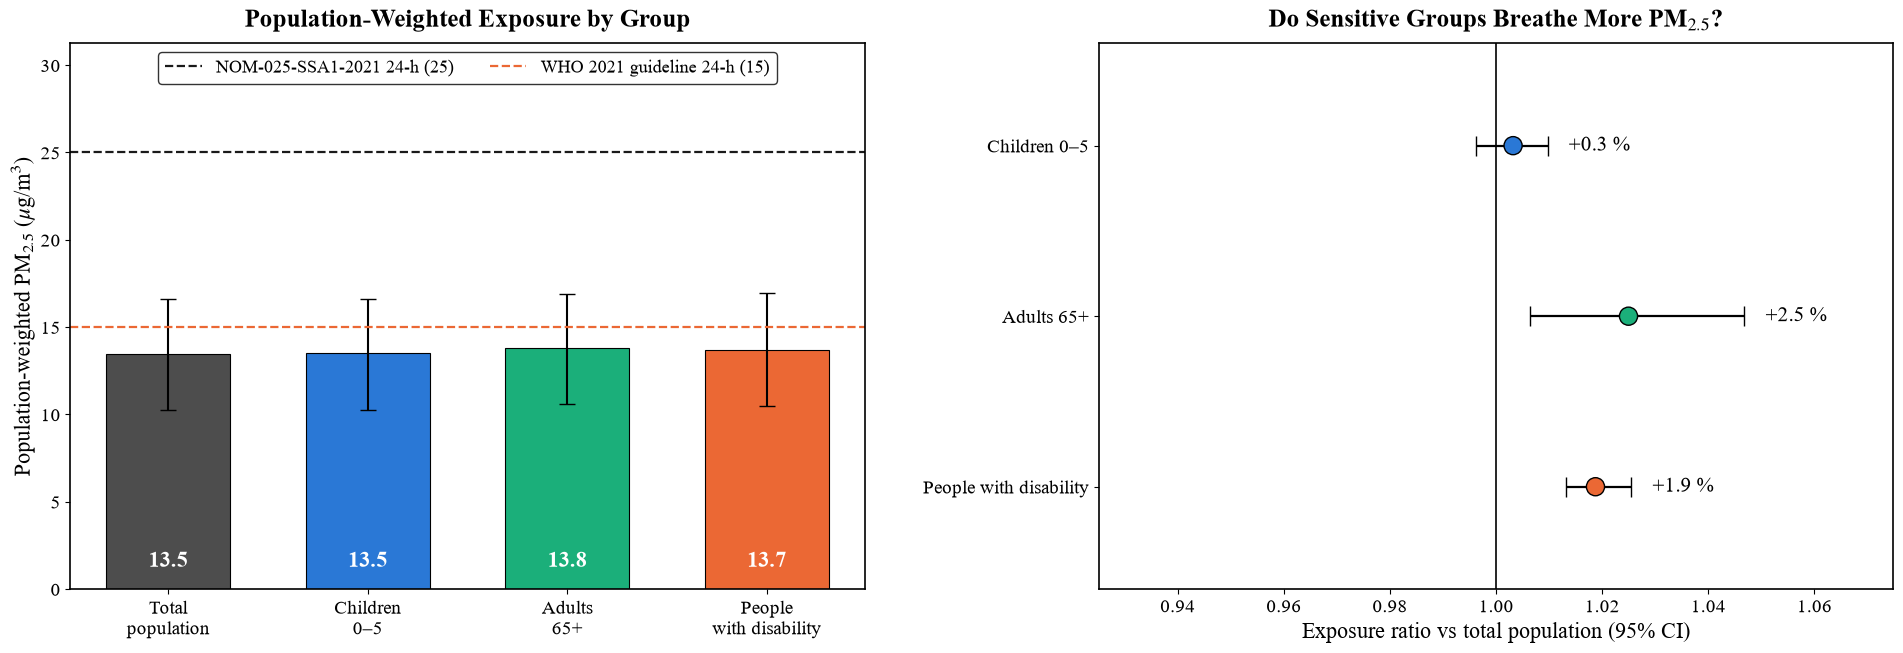

In [3]:
# =============================================================================
# BLOCK 2 · Measure 1: Population-weighted exposure, overall and by sensitive group
# =============================================================================
def pwe(medias, pesos):
    ok = ~np.isnan(medias)
    return np.sum(pesos[ok] * medias[ok]) / np.sum(pesos[ok])


boot_pa = medias_bootstrap(X_pa)                                   # N_BOOT × AGEB
medias_pa = analisis["pm25"].to_numpy(dtype=float)
pesos_total = analisis["pob_total"].to_numpy(dtype=float)
boot_total = np.array([pwe(b, pesos_total) for b in boot_pa])

filas = []
for etiqueta, col in GRUPOS.items():
    pesos = analisis[col].to_numpy(dtype=float)
    dist = np.array([pwe(b, pesos) for b in boot_pa])
    razon = dist / boot_total
    filas.append({"group": etiqueta, "people": pesos.sum(), "PWE": pwe(medias_pa, pesos),
                  "ci_lo": np.nanpercentile(dist, 2.5), "ci_hi": np.nanpercentile(dist, 97.5),
                  "ratio": pwe(medias_pa, pesos) / pwe(medias_pa, pesos_total),
                  "ratio_lo": np.nanpercentile(razon, 2.5), "ratio_hi": np.nanpercentile(razon, 97.5)})
pwe_grupos = pd.DataFrame(filas).set_index("group")
pwe_grupos["different_from_total"] = ~((pwe_grupos["ratio_lo"] <= 1) & (pwe_grupos["ratio_hi"] >= 1))
pwe_sima = pwe(analisis["pm25_SIMA"].to_numpy(dtype=float), pesos_total)

banner("MEASURE 1 · POPULATION-WEIGHTED EXPOSURE TO PM2.5")
tabla(pwe_grupos, 3)
print(f"\nOverall PWE: {pwe_grupos.loc['Total population', 'PWE']:.1f} µg/m³ "
      f"(95% CI {pwe_grupos.loc['Total population', 'ci_lo']:.1f}–{pwe_grupos.loc['Total population', 'ci_hi']:.1f})")
for g in list(GRUPOS)[1:]:
    r = pwe_grupos.loc[g]
    veredicto = "different from" if r["different_from_total"] else "not different from"
    print(f"{g:<24}: {100 * (r['ratio'] - 1):+.1f} % vs total population "
          f"(ratio CI {r['ratio_lo']:.3f}–{r['ratio_hi']:.3f}) -> {veredicto} the total population")
print(f"Reference: SIMA population-weighted exposure in the same AGEBs = {pwe_sima:.1f} µg/m³")
cierre()

# --- Figura ---
fig, axes = nueva_figura(1, 2, (20, 7.5))
ax = axes[0, 0]
x = np.arange(len(pwe_grupos))
colores = [COLOR_GRUPO[g] for g in pwe_grupos.index]
ax.bar(x, pwe_grupos["PWE"], color=colores, edgecolor="black", linewidth=0.8, width=0.62,
       yerr=[pwe_grupos["PWE"] - pwe_grupos["ci_lo"], pwe_grupos["ci_hi"] - pwe_grupos["PWE"]],
       ecolor="black", capsize=6)
for xi, v in zip(x, pwe_grupos["PWE"]):
    ax.text(xi, 1.0, f"{v:.1f}", ha="center", va="bottom", fontsize=16, fontweight="bold", color="white")
for etiqueta, valor in LIMITES.items():
    ax.axhline(valor, color=COLOR_LIMITE[etiqueta], linestyle="--", lw=1.6, label=f"{etiqueta.split(' (')[0]} 24-h ({valor})")
ax.set_xticks(x)
ax.set_xticklabels([g.replace(" ", "\n", 1) for g in pwe_grupos.index])
ax.set_ylim(0, max(LIMITES.values()) * 1.25)
ax.set_ylabel(r"Population-weighted PM$_{2.5}$ ($\mu$g/m$^3$)")
ax.set_title("Population-Weighted Exposure by Group", fontweight="bold", pad=12)
leyenda(ax, loc="upper center", ncol=2, fontsize=13)

ax = axes[0, 1]
grupos = list(GRUPOS)[1:]
y = np.arange(len(grupos))
r = pwe_grupos.loc[grupos]
ax.axvline(1, color="black", lw=1.2)
ax.errorbar(r["ratio"], y, xerr=[r["ratio"] - r["ratio_lo"], r["ratio_hi"] - r["ratio"]], fmt="none",
            ecolor="black", elinewidth=1.6, capsize=7, zorder=2)
ax.scatter(r["ratio"], y, s=170, c=[COLOR_GRUPO[g] for g in grupos], edgecolor="black", zorder=3)
for yi, (_, fila) in zip(y, r.iterrows()):
    ax.text(fila["ratio_hi"] + 0.004, yi, f"{100 * (fila['ratio'] - 1):+.1f} %", va="center", fontsize=15)
ax.set_yticks(y)
ax.set_yticklabels(grupos)
ax.invert_yaxis()
amplitud = max(0.06, np.abs(np.r_[r["ratio_lo"], r["ratio_hi"]] - 1).max() * 1.6)
ax.set_xlim(1 - amplitud, 1 + amplitud)
ax.set_ylim(len(grupos) - 0.4, -0.6)
ax.set_xlabel("Exposure ratio vs total population (95% CI)")
ax.set_title("Do Sensitive Groups Breathe More PM$_{2.5}$?", fontweight="bold", pad=12)
plt.tight_layout(pad=3.0)
guardar(fig, "m1_population_weighted_exposure")
plt.show()

## Measure 2a · Population living above the 24-hour limit

**Objetivo.** Traducir la contaminación a una cifra cotidiana: cuántas personas vivieron cada día en AGEBs cuya media de 24 h rebasó el límite de la **NOM-025-SSA1-2021 (25 µg/m³)** y la **guía de la OMS (15 µg/m³)**.

**Cálculo.**
- Para cada día *d*: población por encima = Σ POBTOT_i de los AGEBs con C_i,d > límite; porcentaje = esa población / población de los AGEBs con dato ese día.
- Resumen: promedio diario de personas y de porcentaje, y el día máximo.
- Se repite por **grado de marginación CONAPO**: porcentaje de la población de cada grado que vive por encima del límite en un día promedio.

> Esto es *exposición estimada por encima del límite*, no incumplimiento legal: el cumplimiento de la NOM se evalúa en estaciones oficiales y con criterios de suficiencia de datos.


 MEASURE 2a · POPULATION LIVING ABOVE THE 24-H LIMIT
Days analysed: 15

NOM-025-SSA1-2021 (25):
  People above the limit on an average day:    159,798  (7.1 % of residents)
  Days with at least one AGEB above the limit: 10 of 15
  Worst day: 2026-11-14 with 779,729 people (34.6 %)

WHO 2021 guideline (15):
  People above the limit on an average day:    869,475  (38.7 % of residents)
  Days with at least one AGEB above the limit: 14 of 15
  Worst day: 2026-11-05 with 2,221,836 people (98.6 %)

-- % of residents above the limit on an average day, by CONAPO marginalization grade --
                  NOM-025-SSA1-2021 (25)  WHO 2021 guideline (15)
Very low                             4.7                     34.8
Low                                  8.6                     40.9
Medium                               9.7                     45.0
High / Very high                    19.2                     52.8



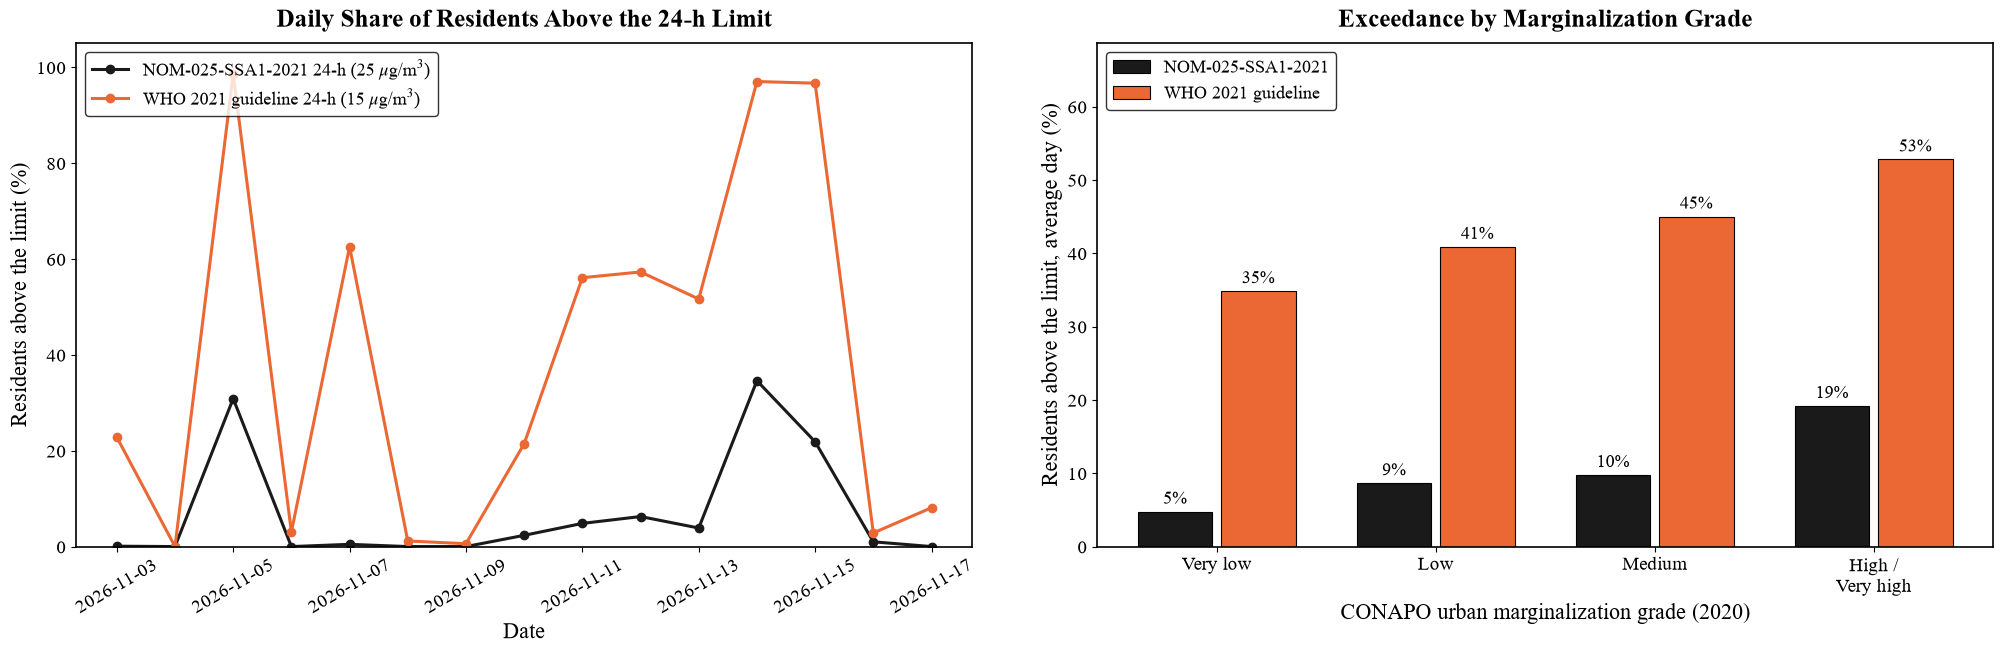

In [4]:
# =============================================================================
# BLOCK 3 · Measure 2a: Population living above the 24-h limit (NOM-025 and WHO)
# =============================================================================
observado = ~np.isnan(X_pa)
pob_obs = (pesos_total[:, None] * observado).sum(axis=0)                 # población con dato, por día

serie = pd.DataFrame(index=dias)
for etiqueta, valor in LIMITES.items():
    sobre = X_pa > valor
    serie[f"people | {etiqueta}"] = (pesos_total[:, None] * sobre).sum(axis=0)
    serie[f"pct | {etiqueta}"] = 100 * serie[f"people | {etiqueta}"] / pob_obs

por_grado = {}
for etiqueta, valor in LIMITES.items():
    sobre = X_pa > valor
    fila = {}
    for grado in CLASES_MG:
        m = (analisis["grado_mg"] == grado).to_numpy()
        p = pesos_total[m][:, None]
        fila[grado] = 100 * np.nanmean((p * sobre[m]).sum(axis=0) / np.maximum((p * observado[m]).sum(axis=0), 1))
    por_grado[etiqueta] = fila
por_grado = pd.DataFrame(por_grado)

banner("MEASURE 2a · POPULATION LIVING ABOVE THE 24-H LIMIT")
print(f"Days analysed: {len(dias)}")
for etiqueta in LIMITES:
    personas, pct = serie[f"people | {etiqueta}"], serie[f"pct | {etiqueta}"]
    print(f"\n{etiqueta}:")
    print(f"  People above the limit on an average day: {personas.mean():>10,.0f}  ({pct.mean():.1f} % of residents)")
    print(f"  Days with at least one AGEB above the limit: {(personas > 0).sum()} of {len(dias)}")
    print(f"  Worst day: {personas.idxmax():%Y-%m-%d} with {personas.max():,.0f} people ({pct.max():.1f} %)")
print("\n-- % of residents above the limit on an average day, by CONAPO marginalization grade --")
tabla(por_grado, 1)
cierre()

# --- Figura ---
fig, axes = nueva_figura(1, 2, (21, 7.5))
ax = axes[0, 0]
for etiqueta in LIMITES:
    ax.plot(serie.index, serie[f"pct | {etiqueta}"], color=COLOR_LIMITE[etiqueta], lw=2.2, marker="o", ms=6,
            label=etiqueta.replace(" (", " 24-h (").replace(")", r" $\mu$g/m$^3$)"))
ax.set_ylim(0, 105)
ax.set_ylabel("Residents above the limit (%)")
ax.set_xlabel("Date")
ax.set_title("Daily Share of Residents Above the 24-h Limit", fontweight="bold", pad=12)
ax.tick_params(axis="x", rotation=30)
leyenda(ax, loc="upper left", fontsize=13)

ax = axes[0, 1]
x = np.arange(len(CLASES_MG))
ancho = 0.38
for k, etiqueta in enumerate(LIMITES):
    valores = por_grado[etiqueta].reindex(CLASES_MG)
    barras = ax.bar(x + (k - 0.5) * ancho, valores, width=ancho - 0.04, color=COLOR_LIMITE[etiqueta],
                    edgecolor="black", linewidth=0.8, label=etiqueta.split(" (")[0])
    ax.bar_label(barras, labels=[f"{v:.0f}%" for v in valores], padding=3, fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels([c.replace(" / ", " /\n") for c in CLASES_MG])
ax.set_ylim(0, max(10, np.nanmax(por_grado.to_numpy()) * 1.3))
ax.set_xlabel("CONAPO urban marginalization grade (2020)")
ax.set_ylabel("Residents above the limit, average day (%)")
ax.set_title("Exceedance by Marginalization Grade", fontweight="bold", pad=12)
leyenda(ax, loc="upper left", fontsize=13)
plt.tight_layout(pad=3.0)
guardar(fig, "m2a_population_above_limit")
plt.show()

## Measure 2b · Concentration curve and concentration index by marginalization

**Objetivo.** Saber si la carga de contaminación se concentra en la población más marginada.

**Cálculo.**
1. Se ordenan los AGEBs del **más marginado al menos marginado** según `IM_2020` (de menor a mayor).
2. **Eje X:** porcentaje acumulado de población.
3. **Eje Y:** porcentaje acumulado de la carga:
   - *Exposición:* personas × PM2.5 medio.
   - *Días-persona sobre la guía de la OMS:* personas × fracción de días por encima de 15 µg/m³.
4. La diagonal es la igualdad perfecta. **Curva por encima de la diagonal → la carga recae más en los marginados.**
5. **Índice de concentración (IC) = 2 × (área bajo la curva) − 1.** Va de −1 a +1; IC > 0 indica carga desigual en contra de los más marginados. IC 95 % por *bootstrap* de días: si incluye 0, no hay evidencia de desigualdad.


 MEASURE 2b · CONCENTRATION INDEX BY CONAPO MARGINALIZATION
AGEBs ranked: 801 | residents: 2,271,403

Exposure burden (people × PM2.5):
  Concentration index: +0.038 (95% CI +0.030 to +0.048) -> burden concentrated among the MOST marginalized
  The 20 % most marginalized residents carry 22.2 % of the burden

Person-days above the WHO guideline:
  Concentration index: +0.068 (95% CI +0.034 to +0.118) -> burden concentrated among the MOST marginalized
  The 20 % most marginalized residents carry 24.4 % of the burden



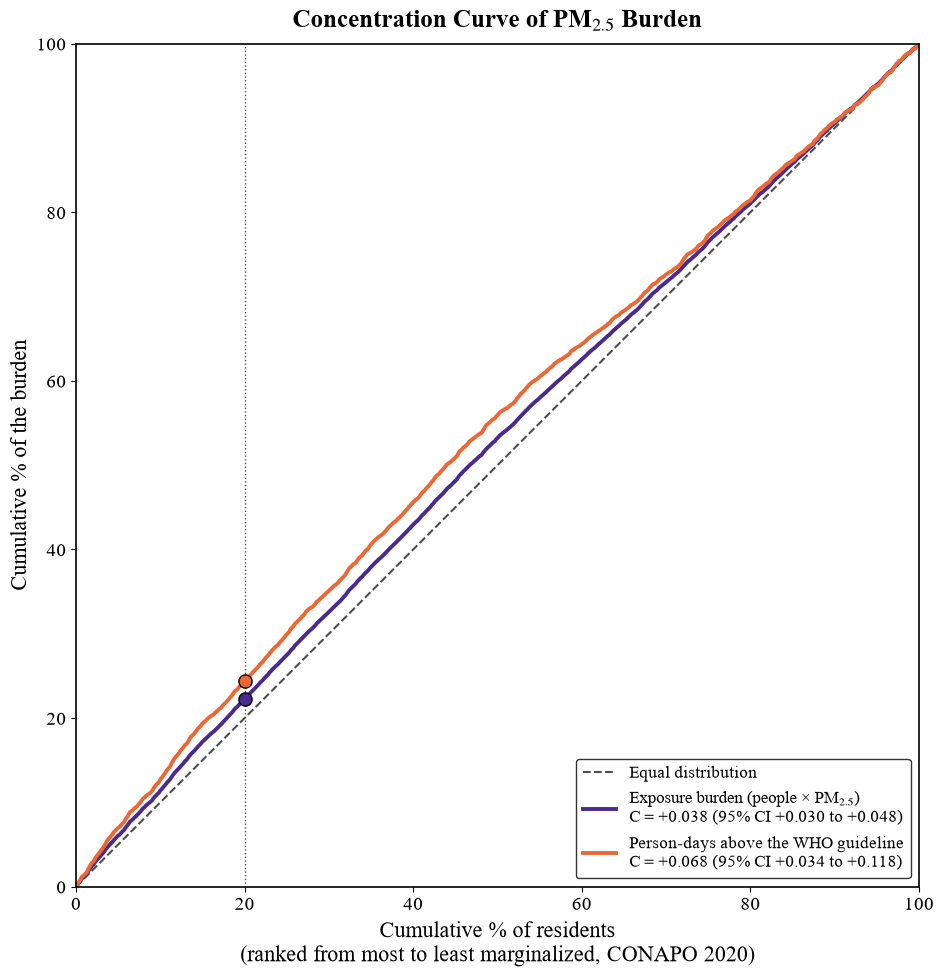

In [5]:
# =============================================================================
# BLOCK 4 · Measure 2b: Concentration curve and index by CONAPO marginalization
# =============================================================================
LIMITE_CURVA = "WHO 2021 guideline (15)"

orden = analisis["im_2020"].notna().to_numpy()
idx = np.where(orden)[0][np.argsort(analisis["im_2020"].to_numpy()[orden], kind="stable")]  # más marginado primero
pob = pesos_total[idx]
x_acum = np.r_[0, np.cumsum(pob)] / pob.sum()


def curva(carga):
    """Curva de concentración (porcentaje acumulado de carga) e índice IC = 2·AUC − 1."""
    carga = np.nan_to_num(carga)
    if carga.sum() <= 0:
        return np.full_like(x_acum, np.nan), np.nan
    y = np.r_[0, np.cumsum(carga)] / carga.sum()
    integrar = getattr(np, "trapezoid", None) or np.trapz
    return y, 2 * integrar(y, x_acum) - 1


obs_sel = observado[idx]
frac_sobre = np.where(obs_sel, X_pa[idx] > LIMITES[LIMITE_CURVA], np.nan)
frac_media = np.nanmean(np.where(obs_sel, frac_sobre, np.nan), axis=1)
boot_frac = medias_bootstrap(frac_sobre)

CARGAS = {
    r"Exposure burden (people × PM$_{2.5}$)": (pob * medias_pa[idx], boot_pa[:, idx] * pob),
    "Person-days above the WHO guideline": (pob * frac_media, boot_frac * pob),
}
resultados_curva = {}
for nombre, (carga, carga_boot) in CARGAS.items():
    y, ic = curva(carga)
    dist = np.array([curva(b)[1] for b in carga_boot])
    resultados_curva[nombre] = {"y": y, "CI": ic, "lo": np.nanpercentile(dist, 2.5), "hi": np.nanpercentile(dist, 97.5),
                                "share_20": 100 * np.interp(0.20, x_acum, y)}

banner("MEASURE 2b · CONCENTRATION INDEX BY CONAPO MARGINALIZATION")
print(f"AGEBs ranked: {len(idx):,} | residents: {pob.sum():,.0f}")
for nombre, r in resultados_curva.items():
    nombre_txt = nombre.replace("$_{2.5}$", "2.5")
    if np.isnan(r["CI"]):
        print(f"\n{nombre_txt}: no burden in the period (nothing to rank)."); continue
    veredicto = ("burden concentrated among the MOST marginalized" if r["lo"] > 0 else
                 "burden concentrated among the LEAST marginalized" if r["hi"] < 0 else "no evidence of inequality")
    print(f"\n{nombre_txt}:")
    print(f"  Concentration index: {r['CI']:+.3f} (95% CI {r['lo']:+.3f} to {r['hi']:+.3f}) -> {veredicto}")
    print(f"  The 20 % most marginalized residents carry {r['share_20']:.1f} % of the burden")
cierre()

# --- Figura ---
fig, axes = nueva_figura(1, 1, (11, 10))
ax = axes[0, 0]
ax.plot([0, 100], [0, 100], color=COLOR_NEUTRO, lw=1.5, linestyle="--", label="Equal distribution")
for (nombre, r), color in zip(resultados_curva.items(), ["#4a2a8f", "#eb6834"]):
    if np.isnan(r["CI"]):
        continue
    ax.plot(100 * x_acum, 100 * r["y"], color=color, lw=2.8,
            label=f"{nombre}\nC = {r['CI']:+.3f} (95% CI {r['lo']:+.3f} to {r['hi']:+.3f})")
    ax.scatter([20], [r["share_20"]], s=90, color=color, edgecolor="black", zorder=4)
ax.axvline(20, color=COLOR_NEUTRO, lw=1, linestyle=":")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_aspect("equal")
ax.set_xlabel("Cumulative % of residents\n(ranked from most to least marginalized, CONAPO 2020)")
ax.set_ylabel("Cumulative % of the burden")
ax.set_title("Concentration Curve of PM$_{2.5}$ Burden", fontweight="bold", pad=12)
leyenda(ax, loc="lower right", fontsize=12)
plt.tight_layout()
guardar(fig, "m2b_concentration_curve")
plt.show()

## Measure 3 · Bivariate local spatial autocorrelation (bivariate LISA)

**Objetivo.** Ubicar en el mapa dónde coinciden la marginación y la contaminación alta (*hotspots* prioritarios).

**Cálculo.**
1. **Variables (estandarizadas, z):** *x* = marginación del AGEB (−`IM_2020`, para que valores altos signifiquen más marginación); *y* = PM2.5 medio del periodo.
2. **Vecinos (W):** contigüidad *queen* (AGEBs que comparten un vértice), normalizada por filas. Los AGEBs sin vecinos dentro del área analizada toman sus 4 vecinos más cercanos.
3. **Estadístico local:** I_i = z_x,i × Σ_j w_ij z_y,j. Compara la marginación del AGEB con la contaminación **de su vecindario**.
4. **Significancia:** 999 permutaciones condicionales y corrección de Benjamini–Hochberg (FDR 5 %) por las cientos de pruebas simultáneas.
5. **Cuadrantes** (solo AGEBs significativos):
   - **Alto–Alto:** zona marginada rodeada de aire contaminado → prioridad de intervención.
   - **Alto–Bajo:** marginada, pero con menor exposición → prioridad social, no ambiental.
   - **Bajo–Alto:** poco marginada y con contaminación alta (verificar uso de suelo antes de interpretarla).
   - **Bajo–Bajo:** poco marginada y con aire más limpio → refugio ambiental relativo.

**Controles de robustez.**
- La superficie de PM2.5 es interpolada (Delaunay) y por construcción suave en el espacio, lo que infla la autocorrelación. Por eso se exige FDR y se repite el análisis con 3 matrices de vecinos (*queen*, 4 y 8 vecinos más cercanos).
- Un AGEB Alto–Alto se considera **robusto** si es significativo en las tres matrices.
- Sensibilidad con otras variables de vulnerabilidad: % sin derechohabiencia (CONAPO) y % de niñas y niños de 0 a 5 años.


 MEASURE 3 · BIVARIATE LISA: MARGINALIZATION × PM2.5
AGEBs: 801 | queen neighbours per AGEB (median): 5 | isolated AGEBs given 4 nearest neighbours: 0

-- Global bivariate Moran's I and significant clusters (FDR 5 %) by spatial weights --
                      Moran_I  p_value  p<0.05_no_FDR  HH  HL  LH   LL
weights                                                               
Queen contiguity        0.265    0.001            321  54  24  40   78
4 nearest neighbours    0.270    0.001            297  42   0  22   19
8 nearest neighbours    0.262    0.001            386  68  42  65  139

-- Clusters (queen, FDR 5 %): AGEBs and residents --
         AGEBs  residents  children_0_5  mean_pm25
cluster                                           
HH          54   176309.0       15425.0       18.8
HL          24    70360.0        6071.0       10.8
LH          40   100632.0        5916.0       17.3
LL          78   267845.0       19531.0        9.9
ns         605  1656257.0      121719.0      

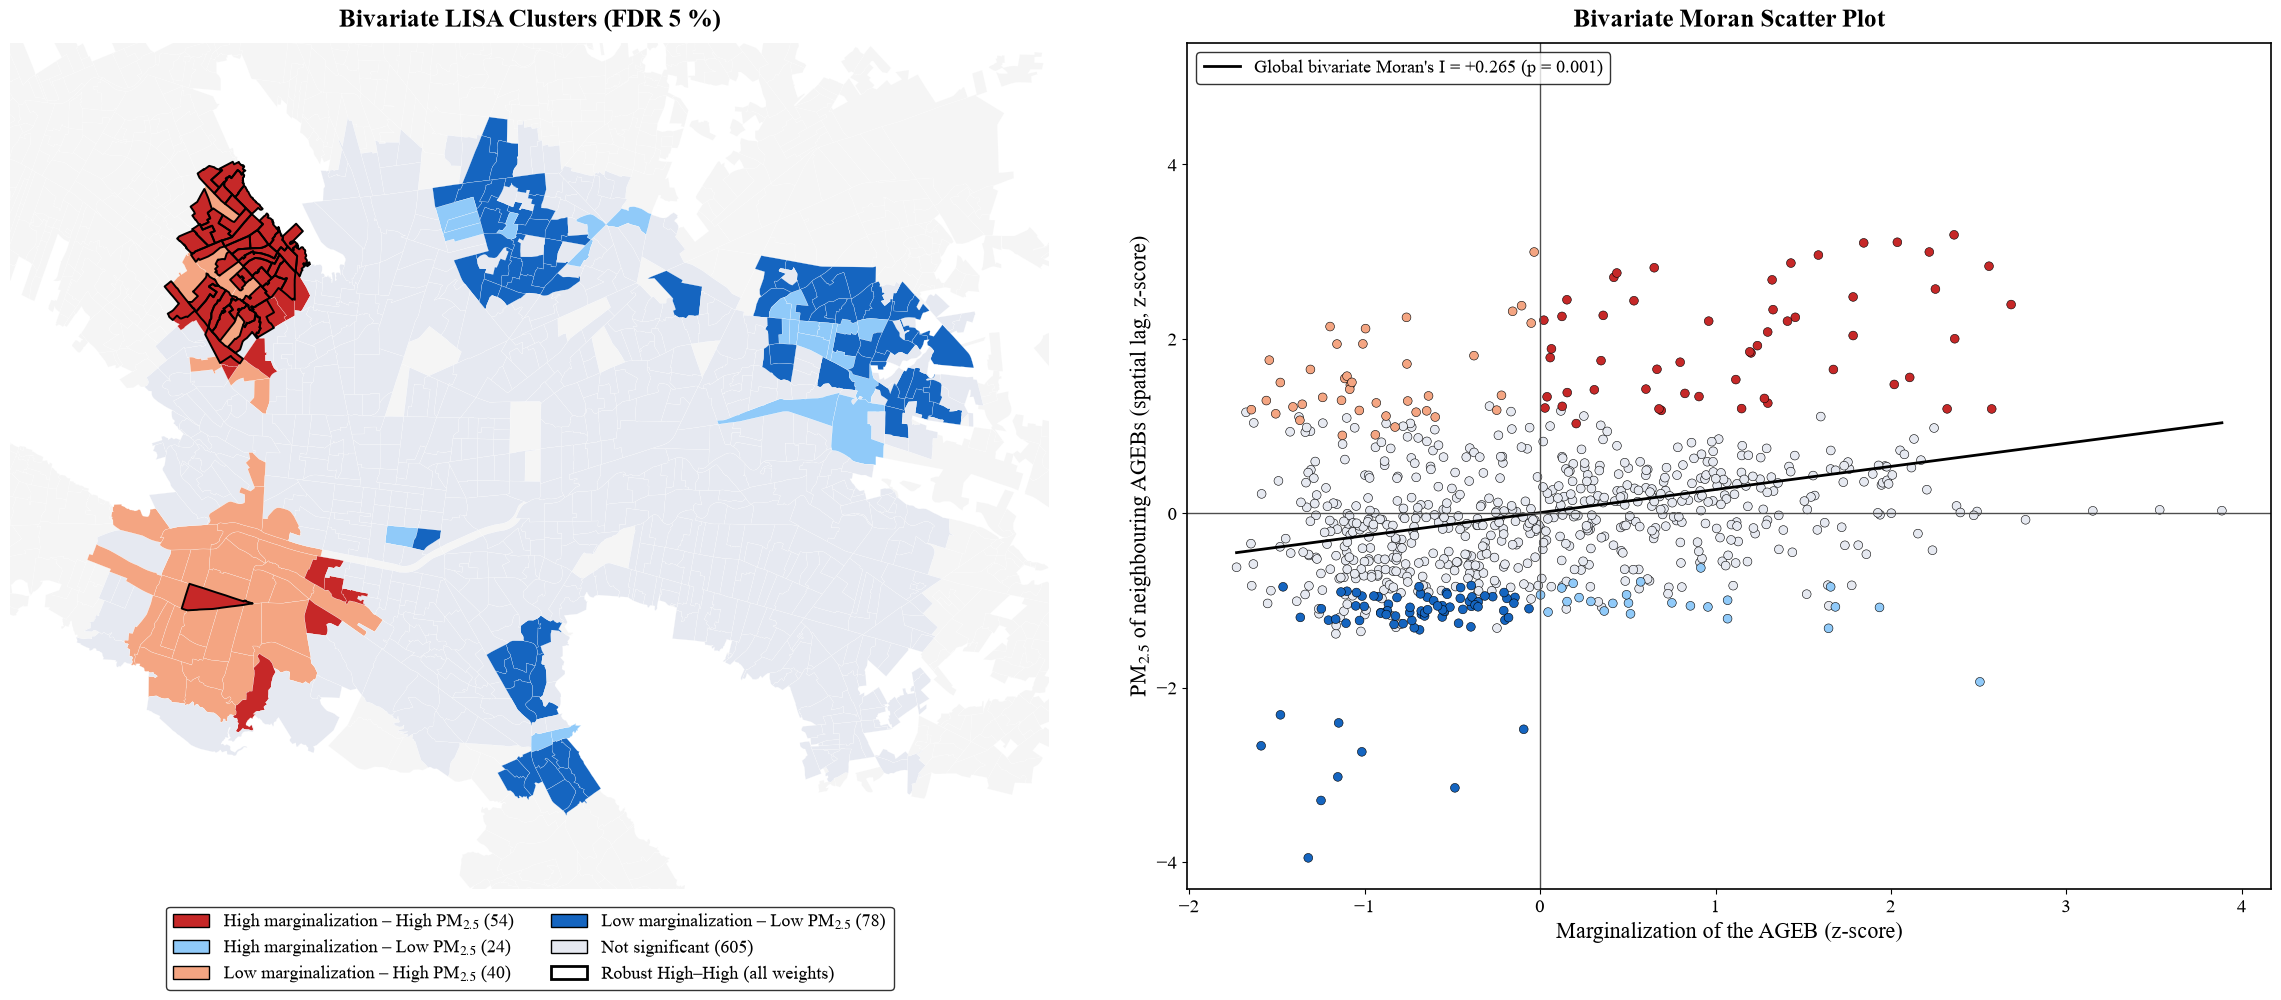

In [6]:
# =============================================================================
# BLOCK 5 · Measure 3: Bivariate LISA (marginalization × PM2.5)
# =============================================================================
lisa = analisis[analisis["im_2020"].notna()].reset_index(drop=True)
n = len(lisa)


def vecinos_queen(geometrias, k_respaldo=4):
    """Vecinos que comparten al menos un vértice; los AGEBs aislados toman sus k vecinos más cercanos."""
    por_vertice = defaultdict(set)
    for i, g in enumerate(geometrias):
        for anillo in anillos_exteriores(g):
            for x, y in np.round(anillo, 6):
                por_vertice[(x, y)].add(i)
    vecinos = [set() for _ in range(len(geometrias))]
    for ids in por_vertice.values():
        for i in ids:
            vecinos[i] |= ids - {i}
    aislados = [i for i, v in enumerate(vecinos) if not v]
    if aislados:
        d = km_haversine(lisa["lat"].to_numpy()[aislados], lisa["lon"].to_numpy()[aislados], lisa["lat"], lisa["lon"])
        for fila, i in zip(d, aislados):
            fila[i] = np.inf
            vecinos[i] = set(np.argsort(fila)[:k_respaldo])
    return [np.array(sorted(v)) for v in vecinos], len(aislados)


def vecinos_knn(k):
    d = km_haversine(lisa["lat"], lisa["lon"], lisa["lat"], lisa["lon"])
    np.fill_diagonal(d, np.inf)
    return [np.argsort(fila)[:k] for fila in d]


def bh_fdr(p, alfa=ALFA_FDR):
    """Benjamini–Hochberg: True donde la prueba es significativa controlando la tasa de falsos descubrimientos."""
    orden_p = np.argsort(p)
    umbral = alfa * np.arange(1, len(p) + 1) / len(p)
    pasa = p[orden_p] <= umbral
    sig = np.zeros(len(p), bool)
    if pasa.any():
        sig[orden_p[:np.max(np.where(pasa)[0]) + 1]] = True
    return sig


def zscore(v):
    v = np.asarray(v, dtype=float)
    return (v - v.mean()) / v.std()


def lisa_bivariado(x, y, vecinos):
    rng = np.random.default_rng(SEMILLA)            # misma semilla en cada corrida: resultados comparables
    zx, zy = zscore(x), zscore(y)
    lag = np.array([zy[v].mean() for v in vecinos])
    I = zx * lag
    # permutaciones condicionales: el valor de x del AGEB se fija y se sortean los vecinos entre los demás AGEBs
    p = np.empty(n)
    for i, v in enumerate(vecinos):
        muestra = rng.integers(0, n - 1, size=(N_PERM, len(v)))
        muestra[muestra >= i] += 1
        I_perm = zx[i] * zy[muestra].mean(axis=1)
        mayores = (I_perm >= I[i]).sum()
        mayores = min(mayores, N_PERM - mayores)
        p[i] = (mayores + 1) / (N_PERM + 1)
    cuadrante = np.select([(zx > 0) & (lag > 0), (zx > 0) & (lag <= 0), (zx <= 0) & (lag > 0)], ["HH", "HL", "LH"], "LL")
    sig = bh_fdr(p)
    # I de Moran bivariado global con permutación de y
    I_global = np.mean(zx * lag)
    perm = np.array([np.mean(zx * np.array([zy_p[v].mean() for v in vecinos]))
                     for zy_p in (rng.permutation(zy) for _ in range(N_PERM))])
    p_global = (np.sum(np.abs(perm) >= abs(I_global)) + 1) / (N_PERM + 1)
    return {"zx": zx, "lag": lag, "I": I, "p": p, "sig": sig, "cuadrante": np.where(sig, cuadrante, "ns"),
            "I_global": I_global, "p_global": p_global, "p05_sin_fdr": int((p < 0.05).sum())}


x_marg = -lisa["im_2020"].to_numpy(dtype=float)                 # más alto = más marginado
y_pm = lisa["pm25"].to_numpy(dtype=float)
w_queen, n_aislados = vecinos_queen(lisa["geometry"].tolist())
MATRICES = {"Queen contiguity": w_queen, "4 nearest neighbours": vecinos_knn(4), "8 nearest neighbours": vecinos_knn(8)}
res_w = {nombre: lisa_bivariado(x_marg, y_pm, w) for nombre, w in MATRICES.items()}
principal = res_w["Queen contiguity"]
lisa["cluster"] = principal["cuadrante"]
lisa["p_lisa"] = principal["p"]
lisa["hh_robusto"] = np.logical_and.reduce([r["cuadrante"] == "HH" for r in res_w.values()])

sensibilidad = {
    "Marginalization (CONAPO IM 2020)": x_marg,
    "% without health coverage (CONAPO)": lisa["pct_sin_salud"].to_numpy(dtype=float),
    "% children 0–5 (census)": (lisa["ninos_0a5"] / lisa["pob_total"]).to_numpy(dtype=float),
}

banner("MEASURE 3 · BIVARIATE LISA: MARGINALIZATION × PM2.5")
print(f"AGEBs: {n:,} | queen neighbours per AGEB (median): {np.median([len(v) for v in w_queen]):.0f} "
      f"| isolated AGEBs given 4 nearest neighbours: {n_aislados}")
print("\n-- Global bivariate Moran's I and significant clusters (FDR 5 %) by spatial weights --")
filas = []
for nombre, r in res_w.items():
    conteo = pd.Series(r["cuadrante"]).value_counts()
    filas.append({"weights": nombre, "Moran_I": r["I_global"], "p_value": r["p_global"],
                  "p<0.05_no_FDR": r["p05_sin_fdr"], **{k: int(conteo.get(k, 0)) for k in ["HH", "HL", "LH", "LL"]}})
tabla(pd.DataFrame(filas).set_index("weights"), 3)
print("\n-- Clusters (queen, FDR 5 %): AGEBs and residents --")
resumen = lisa.groupby("cluster").agg(AGEBs=("cvegeo", "size"), residents=("pob_total", "sum"),
                                      children_0_5=("ninos_0a5", "sum"), mean_pm25=("pm25", "mean"))
tabla(resumen.reindex(["HH", "HL", "LH", "LL", "ns"]).dropna(how="all"), 1)
hh = lisa[lisa["hh_robusto"]]
print(f"\nRobust High–High AGEBs (significant with all three weights): {len(hh)} | residents: {hh['pob_total'].sum():,.0f}")
if len(hh):
    tabla(hh.groupby("municipio").agg(AGEBs=("cvegeo", "size"), residents=("pob_total", "sum"))
          .sort_values("residents", ascending=False), 0)
print("\n-- Sensitivity: other vulnerability variables (queen, FDR 5 %) --")
filas = []
for nombre, xv in sensibilidad.items():
    ok = ~np.isnan(xv)
    if not ok.all():
        xv = np.where(ok, xv, np.nanmedian(xv))
    r = lisa_bivariado(xv, y_pm, w_queen)
    conteo = pd.Series(r["cuadrante"]).value_counts()
    filas.append({"vulnerability variable": nombre, "Moran_I": r["I_global"], "p_value": r["p_global"],
                  **{k: int(conteo.get(k, 0)) for k in ["HH", "HL", "LH", "LL"]}})
tabla(pd.DataFrame(filas).set_index("vulnerability variable"), 3)
print("\nNote: the PM2.5 surface is interpolated and spatially smooth by construction; read clusters as areas,")
print("not as AGEB-level certainties, and prioritise the robust High–High AGEBs.")
cierre()

# --- Figura ---
fig, axes = nueva_figura(1, 2, (24, 10.5))
ax = axes[0, 0]
otros = base[~base["cvegeo"].isin(lisa["cvegeo"])]
dibujar_agebs(ax, otros["geometry"], ["#f5f5f5"] * len(otros), zorder=0)
dibujar_agebs(ax, lisa["geometry"], lisa["cluster"].map(COLOR_LISA), zorder=1)
if len(hh):
    dibujar_agebs(ax, hh["geometry"], ["none"] * len(hh), borde="black", grosor=1.4, zorder=3)
encuadrar(ax, lisa["geometry"], margen=0.02)
conteo = lisa["cluster"].value_counts()
handles = [Patch(facecolor=COLOR_LISA[k], edgecolor="black", label=f"{CUADRANTES[k]} ({conteo.get(k, 0)})")
           for k in ["HH", "HL", "LH", "LL"]]
handles += [Patch(facecolor=COLOR_LISA["ns"], edgecolor="black", label=f"Not significant ({conteo.get('ns', 0)})"),
            Patch(facecolor="white", edgecolor="black", linewidth=2, label="Robust High–High (all weights)")]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=2, frameon=True,
          edgecolor="black", fontsize=13)
ax.set_title("Bivariate LISA Clusters (FDR 5 %)", fontweight="bold", pad=12)

ax = axes[0, 1]
colores = pd.Series(principal["cuadrante"]).map(COLOR_LISA)
orden_dib = np.argsort(principal["cuadrante"] != "ns", kind="stable")     # no significativos al fondo
ax.scatter(principal["zx"][orden_dib], principal["lag"][orden_dib], c=colores.to_numpy()[orden_dib], s=40,
           edgecolor="black", linewidth=0.4)
pendiente = np.polyfit(principal["zx"], principal["lag"], 1)
xx = np.linspace(principal["zx"].min(), principal["zx"].max(), 50)
ax.plot(xx, np.polyval(pendiente, xx), color="black", lw=2,
        label=f"Global bivariate Moran's I = {principal['I_global']:+.3f} (p = {principal['p_global']:.3f})")
ax.axhline(0, color=COLOR_NEUTRO, lw=1)
ax.axvline(0, color=COLOR_NEUTRO, lw=1)
ax.set_xlabel("Marginalization of the AGEB (z-score)")
ax.set_ylabel(r"PM$_{2.5}$ of neighbouring AGEBs (spatial lag, z-score)")
ax.set_title("Bivariate Moran Scatter Plot", fontweight="bold", pad=12)
limite = np.abs(ax.get_ylim()).max()
ax.set_ylim(-limite, limite * 1.25)
leyenda(ax, loc="upper left", fontsize=13)
plt.tight_layout(pad=3.0)
guardar(fig, "m3_bivariate_lisa")
plt.show()

In [7]:
# =============================================================================
# BLOCK 6 · Key findings summary and export
# =============================================================================
pg = pwe_grupos
nom, who = list(LIMITES)
exp = resultados_curva[r"Exposure burden (people × PM$_{2.5}$)"]

banner("KEY FINDINGS")
print(f"1. Exposure: residents breathed on average {pg.loc['Total population', 'PWE']:.1f} µg/m³ of PM2.5 "
      f"(95% CI {pg.loc['Total population', 'ci_lo']:.1f}–{pg.loc['Total population', 'ci_hi']:.1f}).")
for g in list(GRUPOS)[1:]:
    r = pg.loc[g]
    print(f"   {g}: {r['PWE']:.1f} µg/m³ ({100 * (r['ratio'] - 1):+.1f} % vs total; "
          f"{'significant' if r['different_from_total'] else 'not significant'}).")
print(f"2a. Above the limit on an average day: {serie[f'people | {who}'].mean():,.0f} people above the WHO guideline "
      f"({serie[f'pct | {who}'].mean():.1f} %) and {serie[f'people | {nom}'].mean():,.0f} above NOM-025 "
      f"({serie[f'pct | {nom}'].mean():.1f} %).")
print(f"2b. Concentration index of exposure by marginalization: {exp['CI']:+.3f} "
      f"(95% CI {exp['lo']:+.3f} to {exp['hi']:+.3f}); the 20 % most marginalized carry {exp['share_20']:.1f} % of the burden.")
print(f"3. Bivariate LISA: {int((lisa['cluster'] == 'HH').sum())} High–High AGEBs (queen, FDR 5 %), "
      f"{len(hh)} robust across all weights with {hh['pob_total'].sum():,.0f} residents.")
print(f"\nPeriod: {dias.min():%Y-%m-%d} to {dias.max():%Y-%m-%d} ({len(dias)} days). "
      "Results describe this period, not an annual average.")
cierre()

salida = analisis.merge(lisa[["cvegeo", "cluster", "p_lisa", "hh_robusto"]], on="cvegeo", how="left")
salida["pct_dias_sobre_who"] = 100 * np.nanmean(np.where(observado, X_pa > LIMITES[who], np.nan), axis=1)
salida["pct_dias_sobre_nom"] = 100 * np.nanmean(np.where(observado, X_pa > LIMITES[nom], np.nan), axis=1)
columnas = ["cvegeo", "municipio", "lon", "lat", "pm25", "pm25_SIMA", "im_2020", "grado_mg", "pct_sin_salud",
            "pct_dias_sobre_who", "pct_dias_sobre_nom", "cluster", "p_lisa", "hh_robusto", *GRUPOS.values()]
salida[columnas].to_csv(DIR_RESULTADOS / "impacto_social_por_ageb.csv", index=False, encoding="utf-8-sig")
serie.to_csv(DIR_RESULTADOS / "poblacion_sobre_limite_diaria.csv", encoding="utf-8-sig")
print(f"Tables saved to '{DIR_RESULTADOS}' and figures to '{DIR_FIGURAS}'.")


 KEY FINDINGS
1. Exposure: residents breathed on average 13.5 µg/m³ of PM2.5 (95% CI 10.3–16.6).
   Children 0–5: 13.5 µg/m³ (+0.3 % vs total; not significant).
   Adults 65+: 13.8 µg/m³ (+2.5 % vs total; significant).
   People with disability: 13.7 µg/m³ (+1.9 % vs total; significant).
2a. Above the limit on an average day: 869,475 people above the WHO guideline (38.7 %) and 159,798 above NOM-025 (7.1 %).
2b. Concentration index of exposure by marginalization: +0.038 (95% CI +0.030 to +0.048); the 20 % most marginalized carry 22.2 % of the burden.
3. Bivariate LISA: 54 High–High AGEBs (queen, FDR 5 %), 42 robust across all weights with 146,172 residents.

Period: 2026-11-03 to 2026-11-17 (15 days). Results describe this period, not an annual average.

Tables saved to 'resultados_social' and figures to 'figuras_social'.
